# 01 · What does the price we're forecasting look like?

Before improving the model, understand the target. This notebook looks at two years of the
**imbalance price** (the system price the battery settles at) and asks:

1. How is it distributed, and how often is it negative or extreme?
2. When in the day and year is it high?
3. How predictable is it from its own past (why copying a recent day fails)?
4. What drives it, using only information available at the 09:00 decision?
5. How does it relate to the exchange price traded shortly before each half-hour?

Data: the Stage 1 backfill in `data/` (run `make ingest` first). Everything is loaded through
the project's own `History`, so the notebook sees the data exactly as the model does.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import style

from flexcast.backtest import days_between, feature_table
from flexcast.history import History
from flexcast.settlement import LONDON
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
history = History.load(Storage(f"file://{ROOT / 'data'}"))

prices = history.prices.set_index("start_time")["price"]
local = prices.index.tz_convert(LONDON)
print(f"{len(prices):,} half-hours, {local.min():%d %b %Y} to {local.max():%d %b %Y}")

35,040 half-hours, 20 Oct 2024 to 19 Oct 2026


## 1. Distribution: a normal range with long tails

In [2]:
summary = pd.Series(
    {
        "mean £/MWh": prices.mean(),
        "median £/MWh": prices.median(),
        "std dev £/MWh": prices.std(),
        "1st percentile": prices.quantile(0.01),
        "99th percentile": prices.quantile(0.99),
        "max": prices.max(),
        "share negative": (prices < 0).mean(),
        "share above £250": (prices > 250).mean(),
    }
)
summary.to_frame("value").style.format("{:,.2f}")

,value
mean £/MWh,91.25
median £/MWh,92.00
std dev £/MWh,67.69
1st percentile,-25.14
99th percentile,220.00
max,"2,900.00"
share negative,0.06
share above £250,0.00


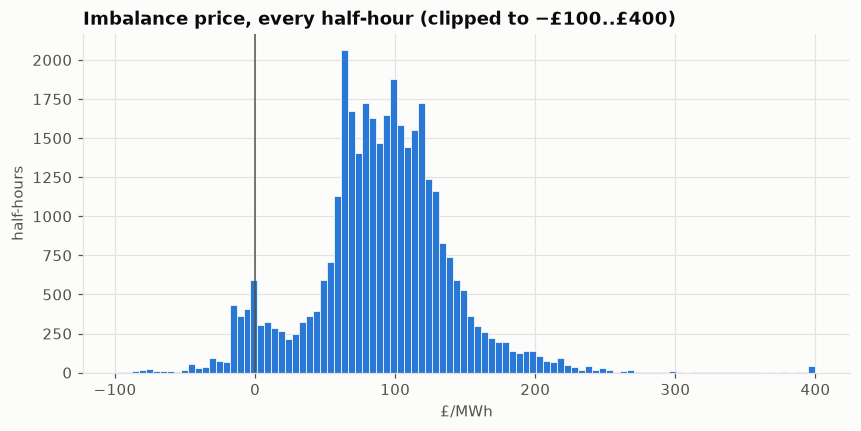

In [3]:
fig, ax = plt.subplots()
clipped = prices.clip(-100, 400)
ax.hist(clipped, bins=100, color=style.BLUE, edgecolor=style.SURFACE, linewidth=0.5)
ax.axvline(0, color=style.TEXT_2, linewidth=1)
ax.set(
    title="Imbalance price, every half-hour (clipped to −£100..£400)",
    xlabel="£/MWh",
    ylabel="half-hours",
)
plt.show()

Most half-hours sit between roughly £50 and £150, but the tails matter for a battery: negative
prices pay you to charge, and spikes are where most of the money is.

## 2. When is it high? Median price by time of day and month

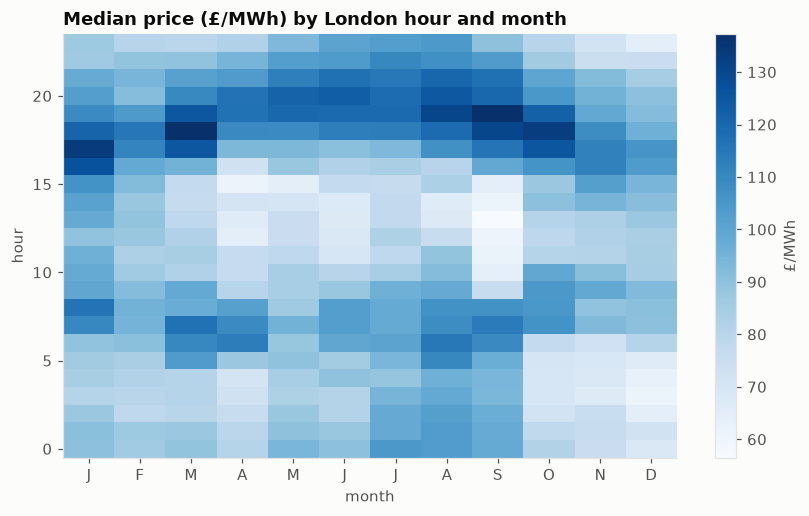

In [4]:
by = pd.DataFrame({"price": prices.values, "hour": local.hour, "month": local.month})
heat = by.pivot_table(index="hour", columns="month", values="price", aggfunc="median")

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heat, aspect="auto", cmap=style.SEQUENTIAL, origin="lower")
ax.set(title="Median price (£/MWh) by London hour and month", xlabel="month", ylabel="hour")
ax.set_xticks(range(12), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.grid(False)
fig.colorbar(im, ax=ax, label="£/MWh")
plt.show()

The daily shape is clear: an evening peak (16:00–19:00) all year, a midday dip in spring and
summer (solar), and higher prices in winter. That shape is what a battery trades. The model's
job is to predict *this day's* version of it.

## 3. How predictable is it from its own past?

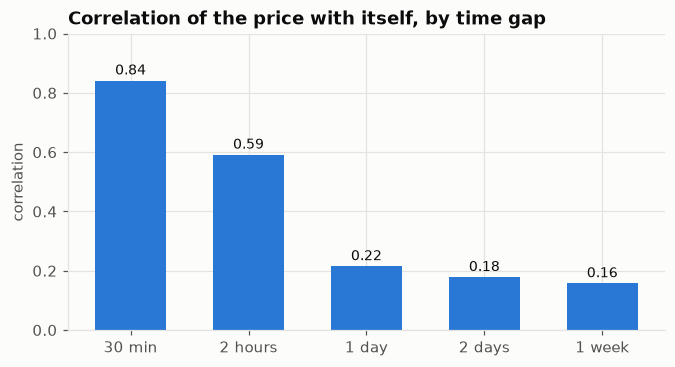

Typical move between consecutive half-hours: £7.3 (median), £17.8 (mean)


In [5]:
lags = {"30 min": 1, "2 hours": 4, "1 day": 48, "2 days": 96, "1 week": 336}
regular = prices.asfreq("30min")
autocorr = pd.Series({name: regular.autocorr(lag) for name, lag in lags.items()})

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(autocorr.index, autocorr.values, color=style.BLUE, width=0.6)
for i, v in enumerate(autocorr.values):
    ax.annotate(
        f"{v:.2f}",
        (i, v),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        color=style.TEXT,
        fontsize=9,
    )
ax.set(title="Correlation of the price with itself, by time gap", ylabel="correlation", ylim=(0, 1))
plt.show()

change = prices.diff().abs()
print(
    f"Typical move between consecutive half-hours: £{change.median():.1f} (median), "
    f"£{change.mean():.1f} (mean)"
)

The price is strongly related to the previous half-hour but only weakly to two days earlier,
which is the most recent complete day at the 09:00 decision. That's why copying "the last
complete day" loses money: it reproduces a shape that has mostly moved on.

## 4. What drives it? Point-in-time drivers

These are the model's inputs exactly as known at each day's 09:00 decision (from
`feature_table`), set against the price that followed.

In [6]:
days = days_between(history.prices["london_date"].min(), history.prices["london_date"].max())
X, y, _ = feature_table(history, days, decision_at=pd.Timestamp("09:00").time())
drivers = X.assign(price=y.values)
print(f"{len(drivers):,} rows of point-in-time features")

35,040 rows of point-in-time features


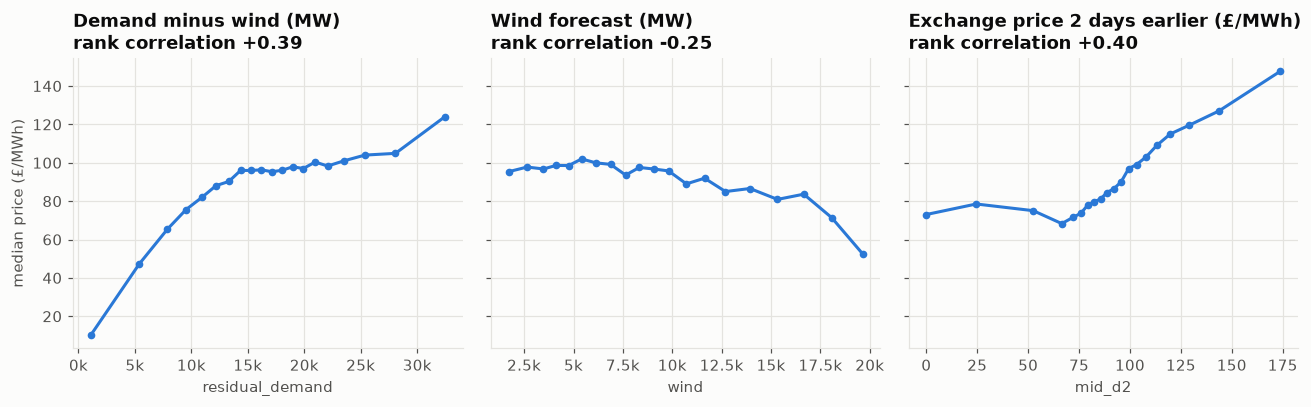

In [7]:
def binned_median(frame: pd.DataFrame, col: str, bins: int = 20) -> pd.Series:
    groups = pd.qcut(frame[col], bins, duplicates="drop")
    return (
        frame.groupby(groups, observed=True)["price"]
        .median()
        .set_axis(frame.groupby(groups, observed=True)[col].median())
    )


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, col, title, color in (
    (axes[0], "residual_demand", "Demand minus wind (MW)", style.BLUE),
    (axes[1], "wind", "Wind forecast (MW)", style.BLUE),
    (axes[2], "mid_d2", "Exchange price 2 days earlier (£/MWh)", style.BLUE),
):
    m = binned_median(drivers, col)
    ax.plot(m.index, m.values, color=color, marker="o", markersize=4)
    if col != "mid_d2":  # MW -> thousands, so tick labels don't collide
        ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:g}k")
    corr = drivers[[col, "price"]].corr(method="spearman").iloc[0, 1]
    ax.set(title=f"{title}\nrank correlation {corr:+.2f}", xlabel=col)
axes[0].set_ylabel("median price (£/MWh)")
plt.tight_layout()
plt.show()

**Demand minus wind** is the clearest driver: it's roughly the demand the gas plants must
cover, and gas sets the price. More wind means lower prices. Solar isn't in the model yet,
and it should behave like wind at midday (checkpoint B).

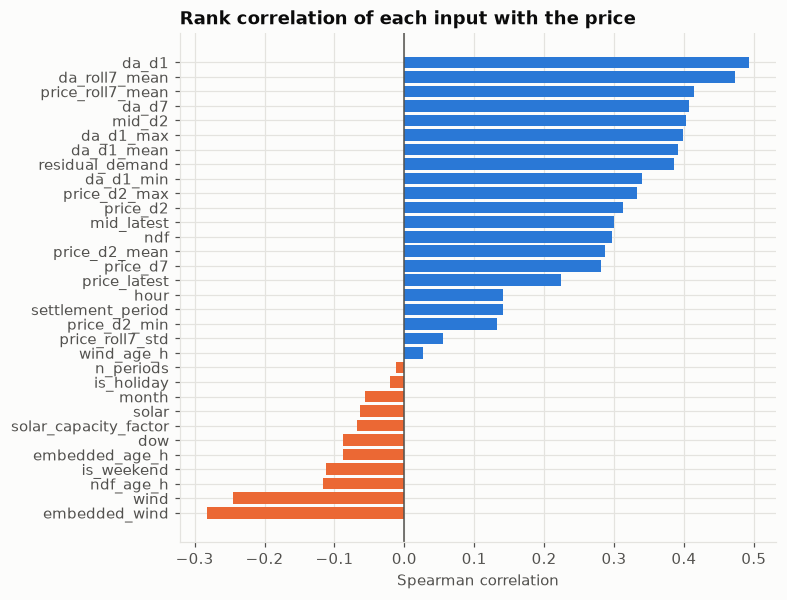

In [8]:
varying = [c for c in drivers.columns if c != "price" and drivers[c].nunique() > 1]
corr = drivers[varying].corrwith(drivers["price"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr.index, corr.values, color=[style.ORANGE if v < 0 else style.BLUE for v in corr])
ax.axvline(0, color=style.TEXT_2, linewidth=1)
ax.set(title="Rank correlation of each input with the price", xlabel="Spearman correlation")
plt.show()

## 5. Spikes and negatives: when do they happen?

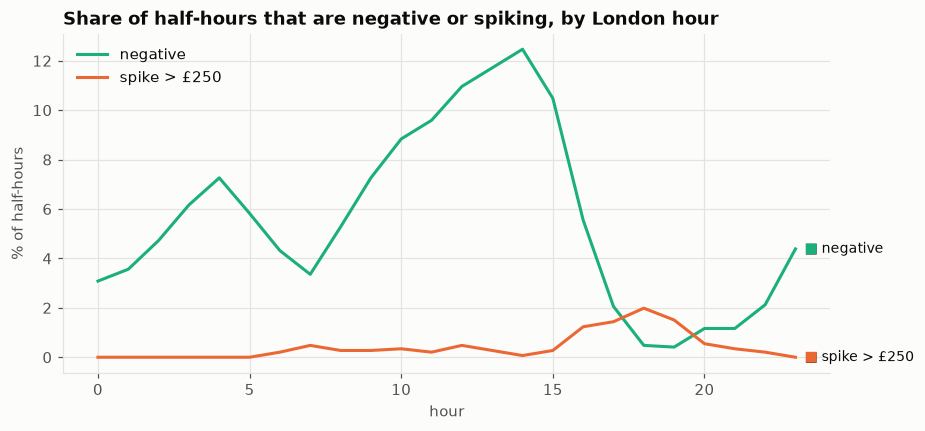

In [9]:
extreme = (
    pd.DataFrame(
        {
            "negative": prices < 0,
            "spike > £250": prices > 250,
            "hour": local.hour,
        }
    )
    .groupby("hour")[["negative", "spike > £250"]]
    .mean()
    * 100
)

fig, ax = plt.subplots()
for col, color in (("negative", style.AQUA), ("spike > £250", style.ORANGE)):
    ax.plot(extreme.index, extreme[col], color=color, label=col)
    style.label_end(ax, extreme.index[-1], extreme[col].iloc[-1], col, color)
ax.set(
    title="Share of half-hours that are negative or spiking, by London hour",
    xlabel="hour",
    ylabel="% of half-hours",
)
ax.legend(loc="upper left")
plt.show()

In [10]:
windy = drivers["wind"] > drivers["wind"].quantile(0.9)
print(
    f"Negative-price share when wind is in its top 10%: {(drivers.price[windy] < 0).mean():.0%} "
    f"vs {(drivers.price[~windy] < 0).mean():.0%} otherwise"
)

Negative-price share when wind is in its top 10%: 14% vs 5% otherwise


Negative prices cluster overnight and at midday (high wind, low demand, solar); spikes cluster
in the evening peak. The battery's money is mostly in those two places, and the model has to
get both the timing and the size right.

## 6. The imbalance price vs the exchange price

The exchange price is set by trading shortly before each half-hour; the imbalance price is
set afterwards by how short or long the whole system was. How closely do they track?

correlation 0.82; imbalance minus exchange: median £0.0, middle 80% from £-31 to £29


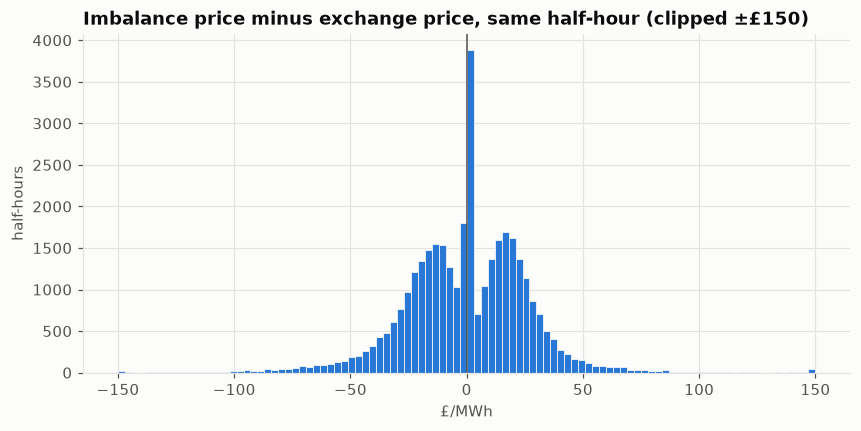

In [11]:
mid = history.mid.set_index("start_time")["price"]
both = pd.DataFrame({"imbalance": prices, "exchange": mid}).dropna()
gap = both["imbalance"] - both["exchange"]
print(
    f"correlation {both.corr().iloc[0, 1]:.2f}; imbalance minus exchange: "
    f"median £{gap.median():.1f}, middle 80% from £{gap.quantile(0.1):.0f} to "
    f"£{gap.quantile(0.9):.0f}"
)

fig, ax = plt.subplots()
ax.hist(gap.clip(-150, 150), bins=100, color=style.BLUE, edgecolor=style.SURFACE, linewidth=0.5)
ax.axvline(0, color=style.TEXT_2, linewidth=1)
ax.set(
    title="Imbalance price minus exchange price, same half-hour (clipped ±£150)",
    xlabel="£/MWh",
    ylabel="half-hours",
)
plt.show()

The two prices are related, but the imbalance price adds a wide, noisy layer on top: whether
the system ended up short or long, which isn't knowable a day ahead. This is the case for
checkpoint D: a battery would normally lock in a price that clears in advance and treat the
imbalance price as a smaller, later adjustment.

## Takeaways for the model

- **Shape is predictable, level is noisy.** The daily and seasonal shape is stable; the size of
  each day's spread is what the model gets wrong (notebook 02).
- **Missing driver: solar.** Midday dips and negative prices follow solar, which the model
  can't see yet → checkpoint B.
- **Tails matter.** Spikes and negatives carry most of the value, so judge changes in £, not
  only average error, and check the p10/p90 band covers them → checkpoint C.
- **The target itself is the hardest one available.** → checkpoint D.